# DermaGen · 01b — Prototype : un premier cVAE

**Objectif :** vérifier rapidement qu'un modèle génératif **conditionnel** apprend à produire des lésions d'un type donné, avant d'écrire la version propre du projet.

On utilise le fichier `hmnist_28_28_RGB.csv` fourni avec le dataset : les 10 015 images y sont déjà réduites en 28×28, ce qui permet de tester en quelques minutes.

> **Limite assumée.** Ce fichier n'a pas de `lesion_id` : on ne peut pas faire le découpage propre par lésion. Ce prototype sert à valider l'idée et le code, **pas** à produire les résultats du projet. Ceux-là viendront avec `src/prepare_data.py` et `src/models/cvae.py`.

## 0. Préparation

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/: go up one level to reach the project root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from src import config, utils

config.ensure_dirs()
utils.set_seed(0)
device = config.get_device()
print("Appareil :", device)

Appareil : cpu


## 1. Charger les images et retrouver les étiquettes

Dans ce fichier, les étiquettes sont des numéros de 0 à 6 qui **ne suivent pas** notre ordre de classes. Comme chaque classe a un effectif différent, on retrouve la correspondance en comparant les effectifs avec ceux des métadonnées : pas besoin de deviner.

In [2]:
hm = pd.read_csv(config.RAW_DIR / "hmnist_28_28_RGB.csv")
meta = pd.read_csv(config.METADATA_CSV)
print("Fichier hmnist :", hm.shape, "→ 28 × 28 × 3 =", 28 * 28 * 3, "pixels + 1 colonne label")

hm_counts = hm["label"].value_counts()
dx_counts = meta["dx"].value_counts()
assert dx_counts.is_unique, "deux classes ont le même effectif : correspondance impossible"
assert sorted(hm_counts) == sorted(dx_counts), "les effectifs ne correspondent pas aux métadonnées"

count_to_dx = {n: dx for dx, n in dx_counts.items()}
hm_to_dx = {int(lab): count_to_dx[n] for lab, n in hm_counts.items()}

(pd.DataFrame({"label hmnist": list(hm_to_dx), "dx": list(hm_to_dx.values())})
   .assign(images=lambda d: d["label hmnist"].map(hm_counts),
           **{"notre label": lambda d: d["dx"].map(config.CLASS_TO_IDX)})
   .sort_values("label hmnist").reset_index(drop=True))

Fichier hmnist : (10015, 2353) → 28 × 28 × 3 = 2352 pixels + 1 colonne label


,label hmnist,dx,images,notre label
0,0,akiec,327,0
1,1,bcc,514,1
2,2,bkl,1099,2
3,3,df,115,3
4,4,nv,6705,5
5,5,vasc,142,6
6,6,mel,1113,4


Images : (10015, 28, 28, 3) | étiquettes : (10015,)


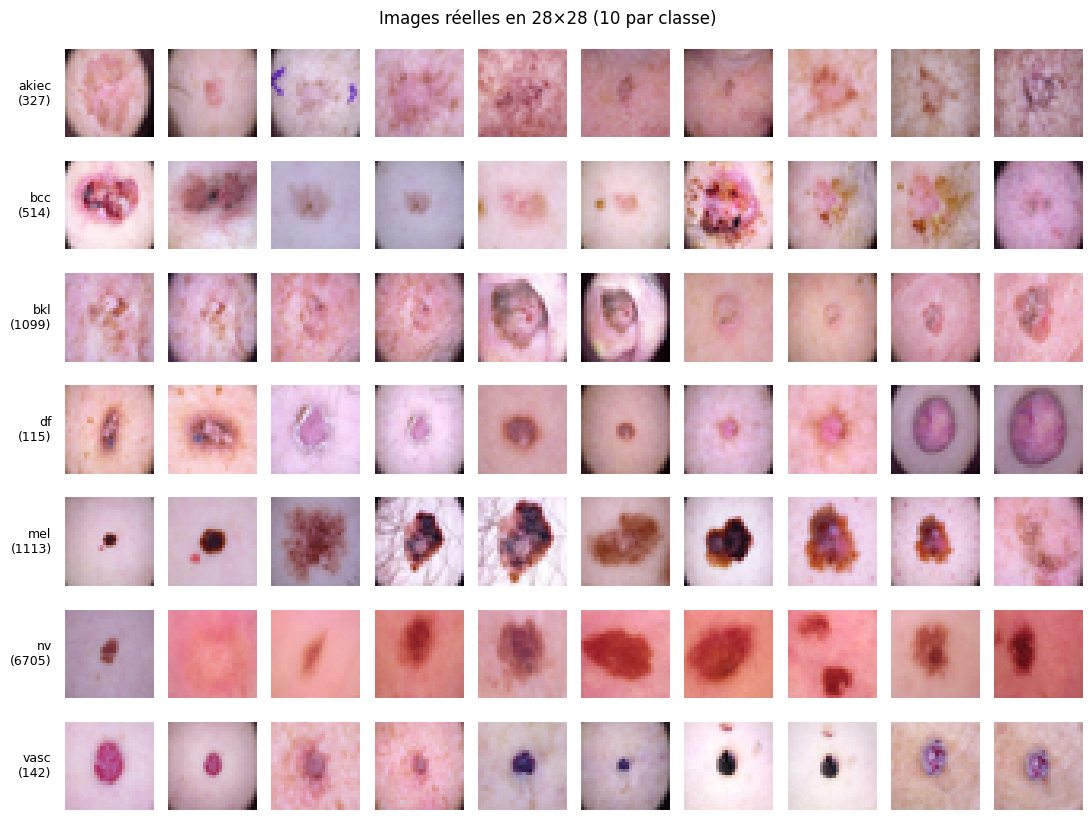

In [3]:
X = hm.drop(columns="label").to_numpy(dtype=np.uint8).reshape(-1, 28, 28, 3)
y = hm["label"].map(hm_to_dx).map(config.CLASS_TO_IDX).to_numpy()
print("Images :", X.shape, "| étiquettes :", y.shape)

fig = utils.plot_class_grid(X, y, n_per_class=10, title="Images réelles en 28×28 (10 par classe)")
plt.show()

## 2. Données d'entraînement

Les pixels passent de [0, 255] à [-1, 1], la convention du projet (le décodeur finit par `tanh`). Découpage **aléatoire** 90 % / 10 %, acceptable uniquement parce que c'est un prototype.

In [4]:
x_all = utils.uint8_to_tensor(X)            # (N, 3, 28, 28), values in [-1, 1]
y_all = torch.from_numpy(y).long()

perm = torch.randperm(len(x_all))
n_val = len(x_all) // 10
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_loader = DataLoader(TensorDataset(x_all[train_idx], y_all[train_idx]), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(x_all[val_idx], y_all[val_idx]), batch_size=512)
print(f"{len(train_idx)} images d'entraînement, {len(val_idx)} de validation")
print(f"Tenseur : {tuple(x_all.shape)}, valeurs dans [{x_all.min():.0f}, {x_all.max():.0f}]")

9014 images d'entraînement, 1001 de validation
Tenseur : (10015, 3, 28, 28), valeurs dans [-1, 1]


## 3. Le modèle : un autoencodeur variationnel conditionnel

- L'**encodeur** $q(z \mid x, y)$ résume une image $x$ de classe $y$ en un petit vecteur latent $z$ (16 nombres).
- Le **décodeur** $p(x \mid z, y)$ reconstruit une image à partir de $z$ et de la classe demandée.
- La classe $y$ est donnée aux deux réseaux sous forme one-hot : c'est ce qui rend le modèle **conditionnel**.

On minimise l'opposé de l'ELBO :

$$
\mathcal{L}(x, y) = \underbrace{\lVert x - \hat{x} \rVert^2}_{\text{reconstruction}} \;+\; \beta \cdot \underbrace{\mathrm{KL}\big(q(z \mid x, y)\,\|\,\mathcal{N}(0, I)\big)}_{\text{régularisation de l'espace latent}}
$$

Pour pouvoir dériver à travers le tirage aléatoire, on utilise l'**astuce de reparamétrisation** : $z = \mu + \sigma \odot \varepsilon$ avec $\varepsilon \sim \mathcal{N}(0, I)$.

Pour **générer**, on tire $z \sim \mathcal{N}(0, I)$ et on le donne au décodeur avec la classe voulue.

In [5]:
class CVAE(nn.Module):
    def __init__(self, latent_dim=16, n_classes=config.NUM_CLASSES, hidden=256):
        super().__init__()
        self.latent_dim, self.n_classes = latent_dim, n_classes
        # Encoder: 3×28×28 -> 32×14×14 -> 64×7×7 -> vector
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.Flatten(),
        )
        self.enc_fc = nn.Sequential(nn.Linear(64 * 7 * 7 + n_classes, hidden), nn.LeakyReLU(0.2))
        self.mu = nn.Linear(hidden, latent_dim)
        self.logvar = nn.Linear(hidden, latent_dim)
        # Decoder: (z, y) -> 64×7×7 -> 32×14×14 -> 3×28×28
        self.dec_fc = nn.Sequential(
            nn.Linear(latent_dim + n_classes, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 64 * 7 * 7), nn.LeakyReLU(0.2),
        )
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh(),
        )

    def one_hot(self, y):
        return F.one_hot(y, self.n_classes).float()

    def encode(self, x, y):
        h = self.enc_fc(torch.cat([self.enc(x), self.one_hot(y)], dim=1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, y):
        h = self.dec_fc(torch.cat([z, self.one_hot(y)], dim=1))
        return self.dec(h.view(-1, 64, 7, 7))

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterization trick
        return self.decode(z, y), mu, logvar

    @torch.no_grad()
    def sample(self, labels):
        """Same interface as every generator of the project: class indices -> images in [-1, 1]."""
        z = torch.randn(len(labels), self.latent_dim, device=labels.device)
        return self.decode(z, labels)


def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec = F.mse_loss(x_hat, x, reduction="sum") / len(x)                      # per image
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)     # per image
    return rec + beta * kl, rec, kl


model = CVAE().to(device)
print(f"{utils.count_parameters(model):,} paramètres entraînables".replace(",", " "))

1 694 179 paramètres entraînables


## 4. Entraînement

20 époques, β = 1. Compter quelques minutes sur un processeur, moins d'une minute sur GPU. Chaque époque est enregistrée dans `results/logs/proto_cvae_s0.csv` grâce au `RunLogger` de `src/utils.py`.

In [6]:
EPOCHS, BETA, LR = 20, 1.0, 1e-3
opt = torch.optim.Adam(model.parameters(), lr=LR)
logger = utils.RunLogger("proto_cvae_s0", {
    "epochs": EPOCHS, "beta": BETA, "lr": LR, "latent_dim": model.latent_dim,
    "data": "hmnist_28_28_RGB, random split (prototype)",
})
utils.reset_peak_memory()
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = rec_sum = kl_sum = 0.0
    with utils.Timer() as timer:
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            x_hat, mu, logvar = model(xb, yb)
            loss, rec, kl = vae_loss(x_hat, xb, mu, logvar, BETA)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            rec_sum += rec.item() * len(xb)
            kl_sum += kl.item() * len(xb)

    model.eval()
    val = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            x_hat, mu, logvar = model(xb, yb)
            val += vae_loss(x_hat, xb, mu, logvar, BETA)[0].item() * len(xb)

    n_tr, n_va = len(train_loader.dataset), len(val_loader.dataset)
    row = dict(epoch=epoch, loss=total / n_tr, rec=rec_sum / n_tr, kl=kl_sum / n_tr,
               val_loss=val / n_va, epoch_s=round(timer.seconds, 1))
    history.append(row)
    logger.log(**row)

logger.close(final_val_loss=history[-1]["val_loss"])

epoch 1 | loss 186.85 | rec 171.73 | kl 15.124 | val_loss 73.63 | epoch_s 2.8 | elapsed_s 2.9
epoch 2 | loss 65.999 | rec 49.805 | kl 16.194 | val_loss 58.092 | epoch_s 2.5 | elapsed_s 5.5
epoch 3 | loss 57.674 | rec 41.417 | kl 16.257 | val_loss 55.19 | epoch_s 2.4 | elapsed_s 7.9
epoch 4 | loss 54.253 | rec 38.095 | kl 16.158 | val_loss 52.136 | epoch_s 2.2 | elapsed_s 10.2
epoch 5 | loss 52.097 | rec 36.111 | kl 15.985 | val_loss 51.542 | epoch_s 2.3 | elapsed_s 12.6
epoch 6 | loss 50.568 | rec 34.697 | kl 15.871 | val_loss 49.155 | epoch_s 2.4 | elapsed_s 15
epoch 7 | loss 49.822 | rec 34.005 | kl 15.817 | val_loss 48.656 | epoch_s 2.4 | elapsed_s 17.5
epoch 8 | loss 49.502 | rec 33.794 | kl 15.708 | val_loss 48.104 | epoch_s 2.3 | elapsed_s 19.9
epoch 9 | loss 48.946 | rec 33.237 | kl 15.709 | val_loss 47.038 | epoch_s 2.3 | elapsed_s 22.3
epoch 10 | loss 48.228 | rec 32.549 | kl 15.679 | val_loss 46.652 | epoch_s 2.3 | elapsed_s 24.7
epoch 11 | loss 47.429 | rec 31.478 | kl 15.95

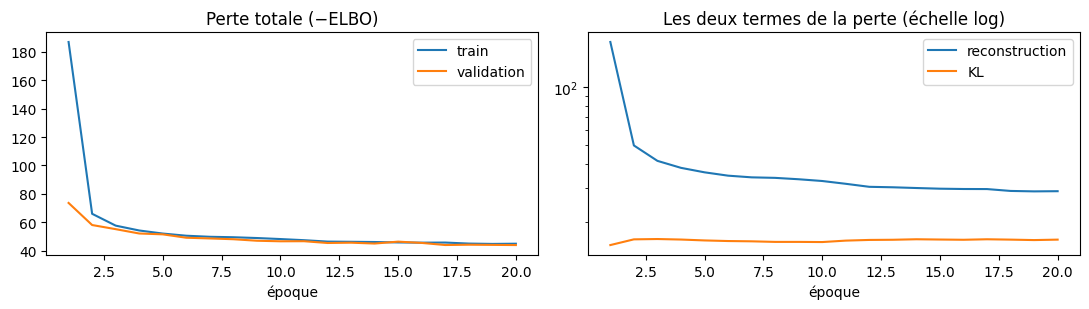

In [7]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(h["epoch"], h["loss"], label="train")
axes[0].plot(h["epoch"], h["val_loss"], label="validation")
axes[0].set_title("Perte totale (−ELBO)"); axes[0].set_xlabel("époque"); axes[0].legend()
axes[1].plot(h["epoch"], h["rec"], label="reconstruction")
axes[1].plot(h["epoch"], h["kl"], label="KL")
axes[1].set_yscale("log")
axes[1].set_title("Les deux termes de la perte (échelle log)"); axes[1].set_xlabel("époque"); axes[1].legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01b_proto_losses.png", dpi=150)
plt.show()

## 5. Résultats

### 5.1 Reconstructions

On encode des images de validation, puis on les décode à partir de la moyenne $\mu$ (sans tirage aléatoire).

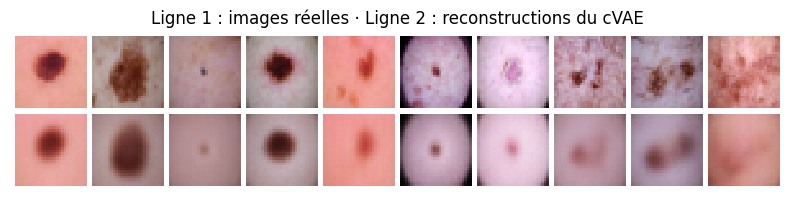

In [8]:
model.eval()
xb, yb = next(iter(val_loader))
xb, yb = xb[:10].to(device), yb[:10].to(device)
with torch.no_grad():
    mu, _ = model.encode(xb, yb)
    x_rec = model.decode(mu, yb)

plt.figure(figsize=(10, 2.4))
plt.imshow(utils.make_grid(torch.cat([xb, x_rec]).cpu(), nrow=10), interpolation="nearest")
plt.axis("off")
plt.title("Ligne 1 : images réelles · Ligne 2 : reconstructions du cVAE")
plt.show()

### 5.2 Génération : 10 images par classe

On tire $z \sim \mathcal{N}(0, I)$ et on demande chaque classe au décodeur.

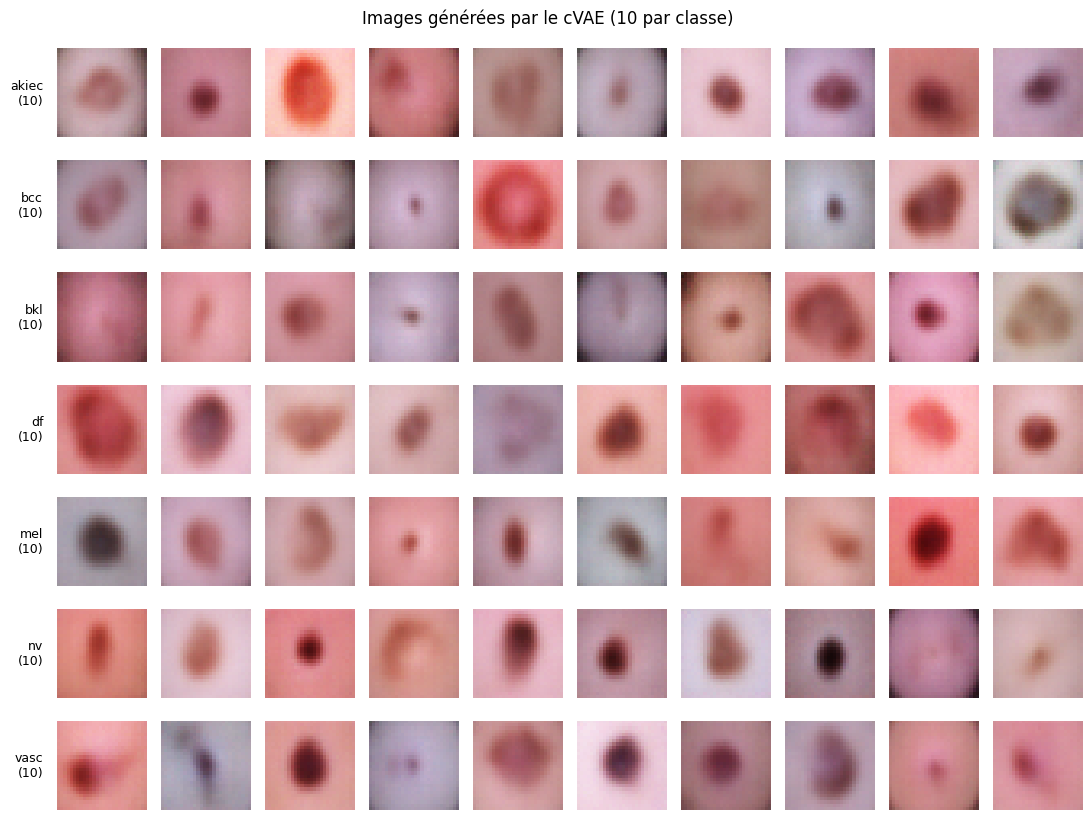

In [9]:
labels = torch.arange(config.NUM_CLASSES, device=device).repeat_interleave(10)
generated = model.sample(labels).cpu()

fig = utils.plot_class_grid(generated, labels.cpu().numpy(), n_per_class=10,
                            path=config.FIGURES_DIR / "01b_proto_samples.png",
                            title="Images générées par le cVAE (10 par classe)")
plt.show()

### 5.3 Même $z$, classe différente : le conditionnement

Chaque colonne garde **le même** vecteur $z$ ; seule la classe demandée change d'une ligne à l'autre. Si le conditionnement fonctionne, la classe change l'aspect de la lésion, tandis que $z$ garde des traits communs (position, taille, éclairage).

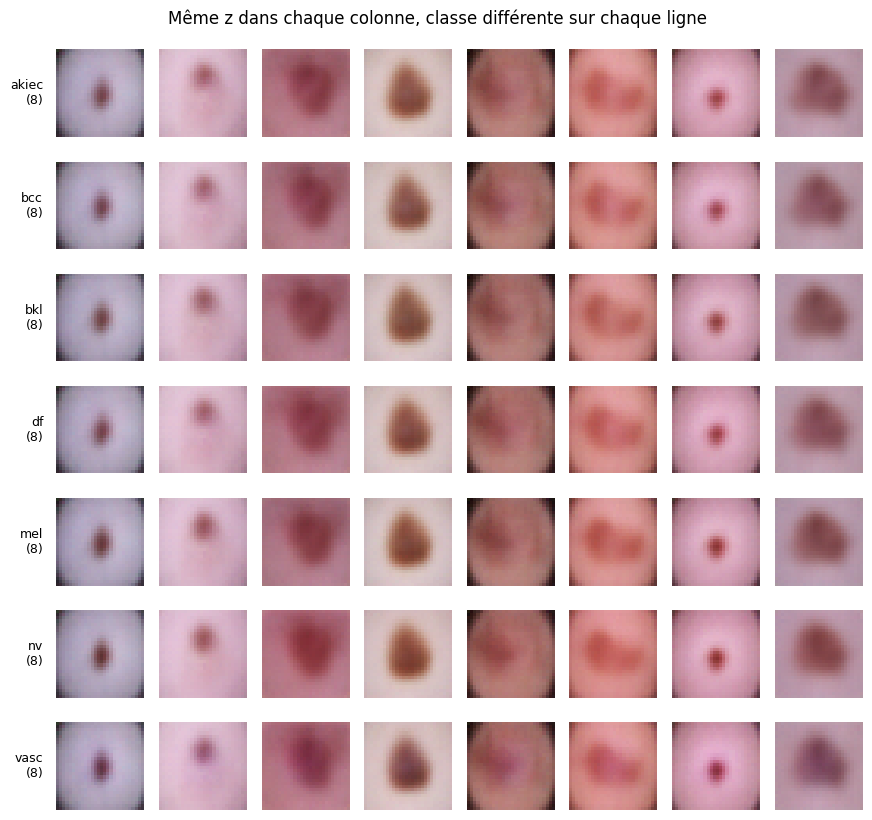

In [10]:
n = 8
z = torch.randn(n, model.latent_dim, device=device)
with torch.no_grad():
    swap = torch.cat([model.decode(z, torch.full((n,), c, device=device)) for c in range(config.NUM_CLASSES)])
swap_labels = np.repeat(np.arange(config.NUM_CLASSES), n)

fig = utils.plot_class_grid(swap.cpu(), swap_labels, n_per_class=n,
                            path=config.FIGURES_DIR / "01b_proto_class_swap.png",
                            title="Même z dans chaque colonne, classe différente sur chaque ligne")
plt.show()

### 5.4 Interpolation dans l'espace latent

On passe progressivement d'un vecteur $z_0$ à un vecteur $z_1$, pour la classe mélanome. Un espace latent bien régularisé (grâce au terme KL) donne une transition continue.

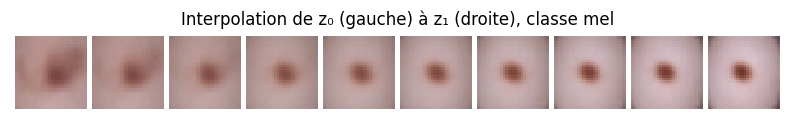

In [11]:
c = config.CLASS_TO_IDX["mel"]
z0, z1 = torch.randn(2, model.latent_dim, device=device)
alphas = torch.linspace(0, 1, 10, device=device)
zs = torch.stack([(1 - a) * z0 + a * z1 for a in alphas])
with torch.no_grad():
    path_imgs = model.decode(zs, torch.full((10,), c, device=device)).cpu()

plt.figure(figsize=(10, 1.6))
plt.imshow(utils.make_grid(path_imgs, nrow=10), interpolation="nearest")
plt.axis("off")
plt.title("Interpolation de z₀ (gauche) à z₁ (droite), classe mel")
plt.show()

In [12]:
ckpt = utils.save_checkpoint(config.CHECKPOINT_DIR / "proto_cvae_s0.pt", EPOCHS,
                             {"model": model}, {"opt": opt}, logger.info["config"])
print("Prototype sauvegardé :", ckpt.relative_to(config.ROOT))

Prototype sauvegardé : checkpoints\proto_cvae_s0.pt


## 6. Bilan du prototype

**Ce que ce prototype vérifie**

- La chaîne complète fonctionne : chargement, entraînement, génération par classe, sauvegarde.
- Le conditionnement par la classe est en place (section 5.3).
- Les outils communs du projet (`config.py`, `utils.py`) sont utilisés tels quels.

**Limites connues, traitées dans la version finale**

| Limite du prototype | Version finale |
|---|---|
| Découpage aléatoire, sans `lesion_id` | Découpage par lésion avec `src/prepare_data.py` |
| Images redimensionnées sans recadrage | Recadrage central puis 28×28 (voir notebook 01) |
| Perte MSE : images floues, typique d'un VAE | Comparaison avec un GAN et un modèle de diffusion |
| Pas de métrique chiffrée | FID, KID, précision / rappel, fidélité, CAS |
| Un seul réglage (β = 1, z de dimension 16) | Ablations sur β et sur la dimension latente |

**Étapes suivantes :** `src/prepare_data.py`, puis `src/models/cvae.py` et `src/train_cvae.py` (semaine 2).